<a href="https://colab.research.google.com/github/maisafabrega-bot/nlp-research-gaps-usp/blob/main/thesis_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Select the octoparse_thesis_scraping.csv file from your computer:


Saving octoparse_thesis_scraping.csv to octoparse_thesis_scraping (9).csv
127 works loaded.
Period: 1988 to 2026


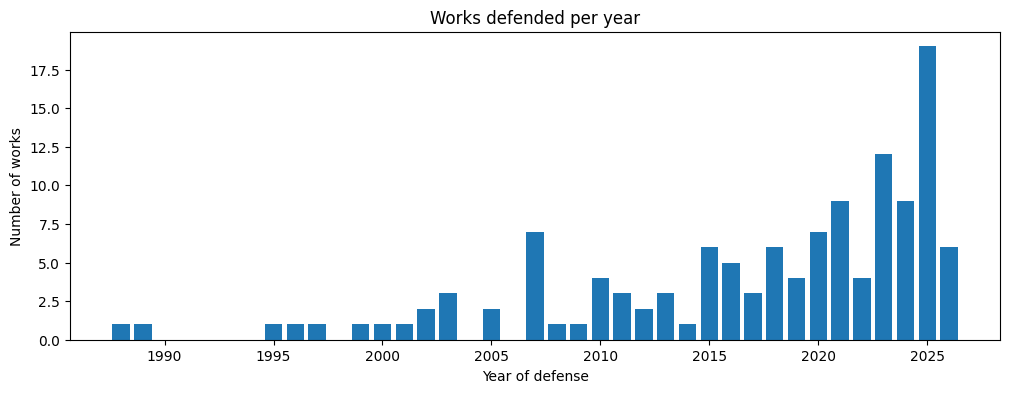

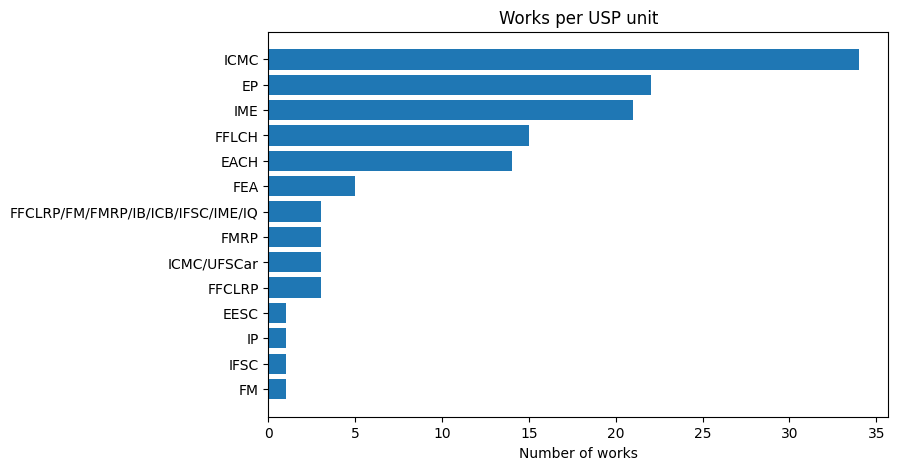

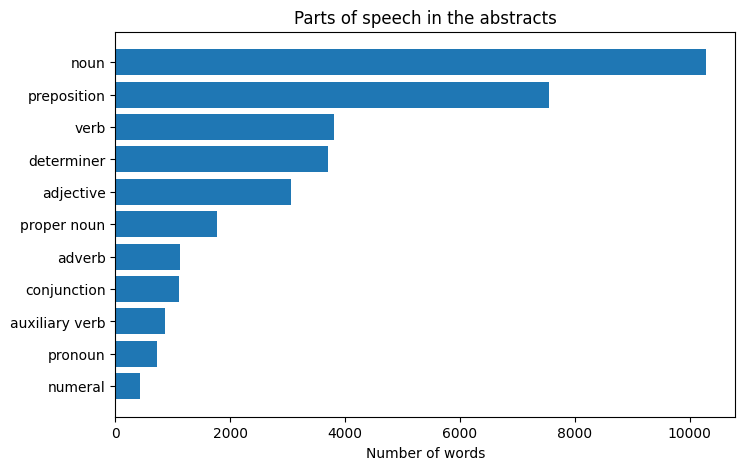

Distinct words: 2493
Distinct noun phrases: 2283


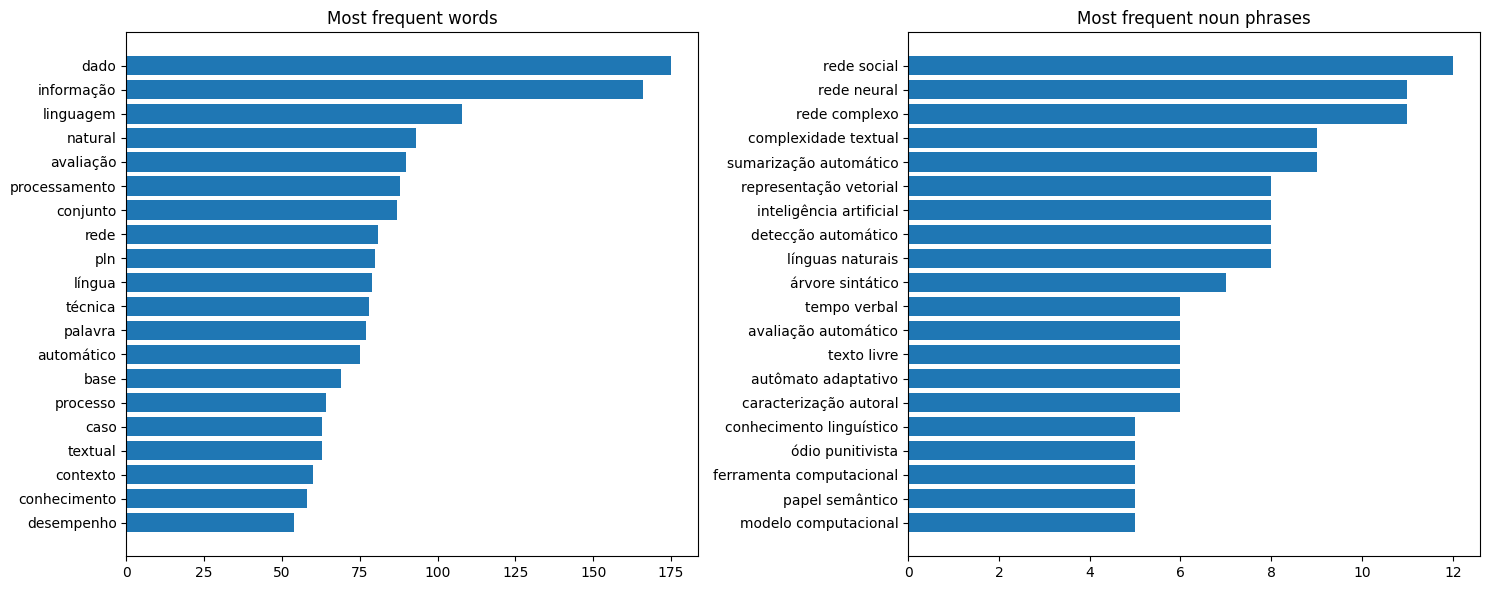

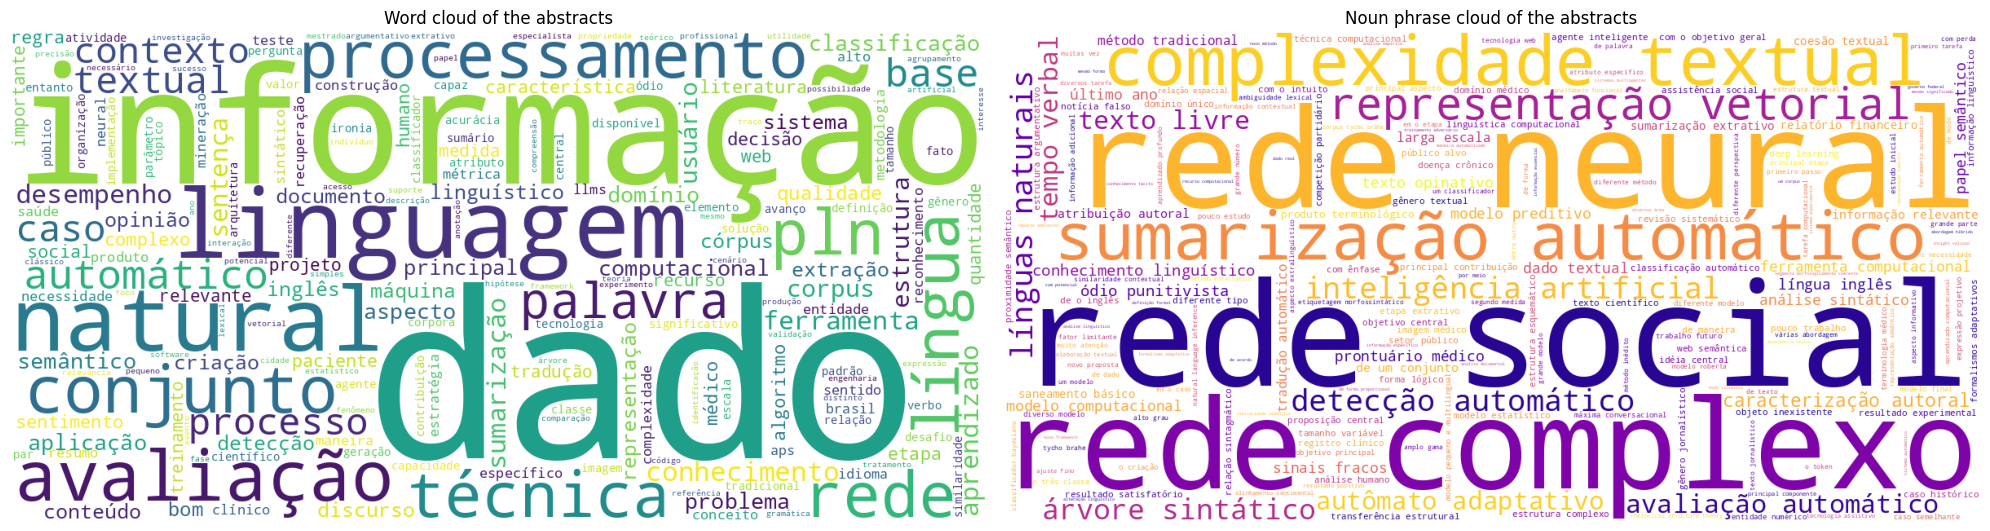

Works with no task identified: 34 of 127
Works with no methodology identified: 50 of 127


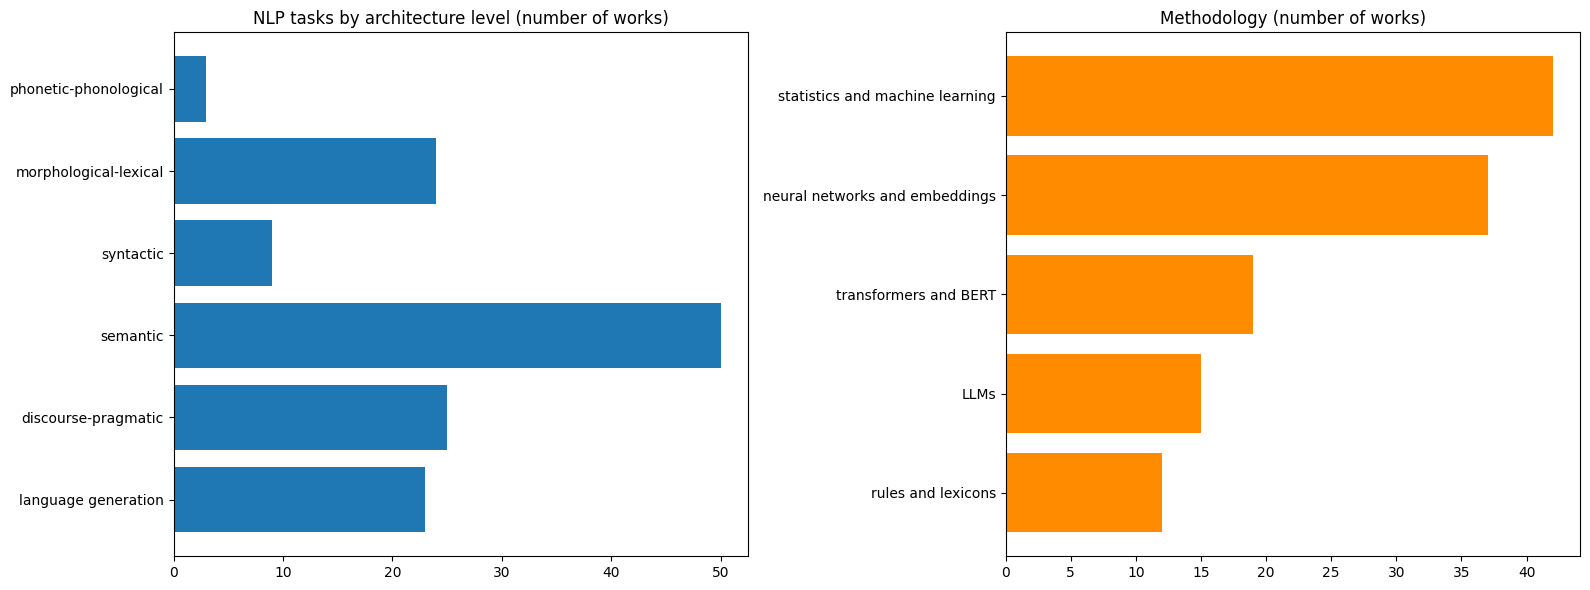

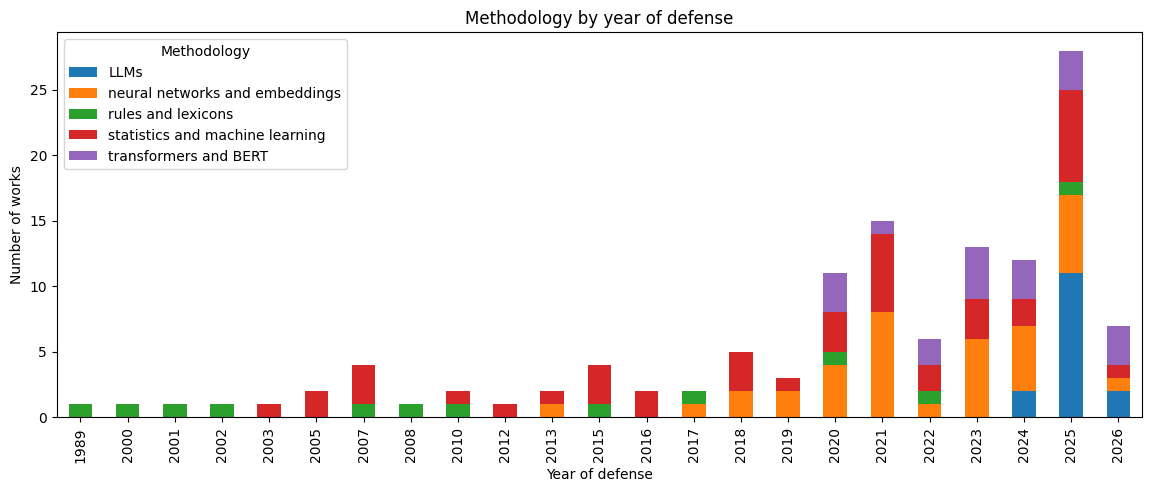

,topic,number of works
0,"informação, pln, médico",28
1,"sumarização, opinião, sumário",14
2,"corpus, sintático, aps",24
3,"palavra, rede, representação",19
4,"sentimento, dado, classificação",34
5,"discurso, ódio, discurso ódio",8


,automatic name,thematic name
0,"informação, pln, médico",Information extraction and retrieval in health...
1,"sumarização, opinião, sumário",Automatic summarization and opinion summarization
2,"corpus, sintático, aps",Corpora and syntactic analysis
3,"palavra, rede, representação",Complex networks and vector representation of ...
4,"sentimento, dado, classificação","Sentiment, stance and irony classification"
5,"discurso, ódio, discurso ódio",Discourse structure and hate speech


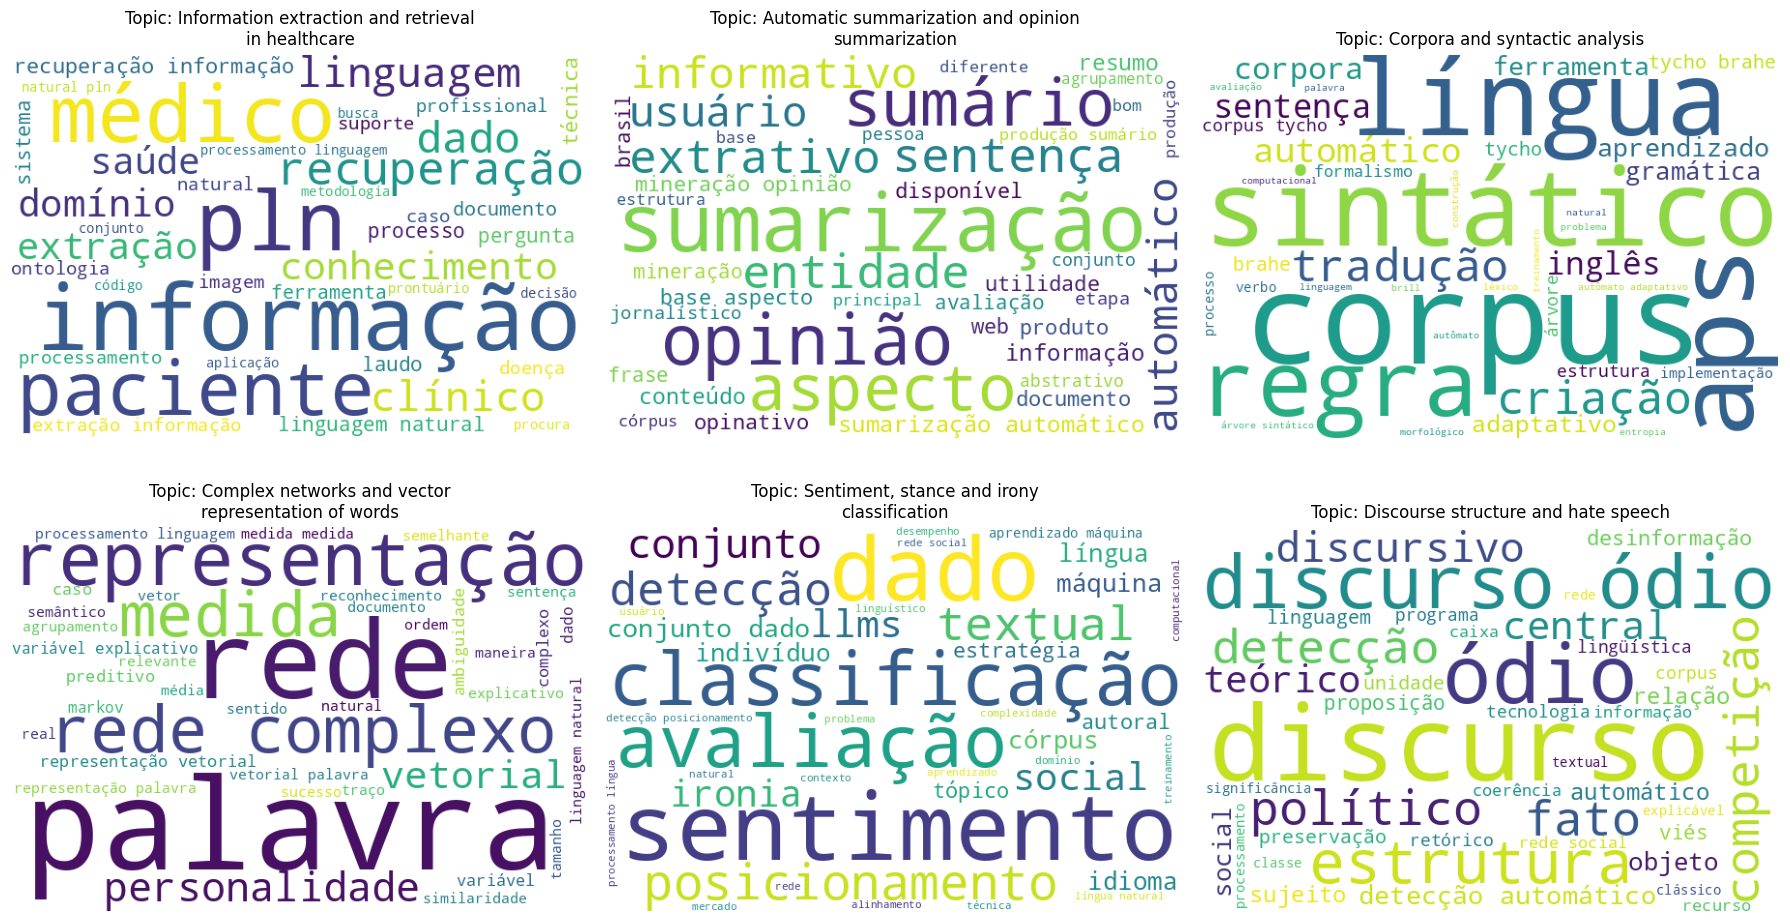

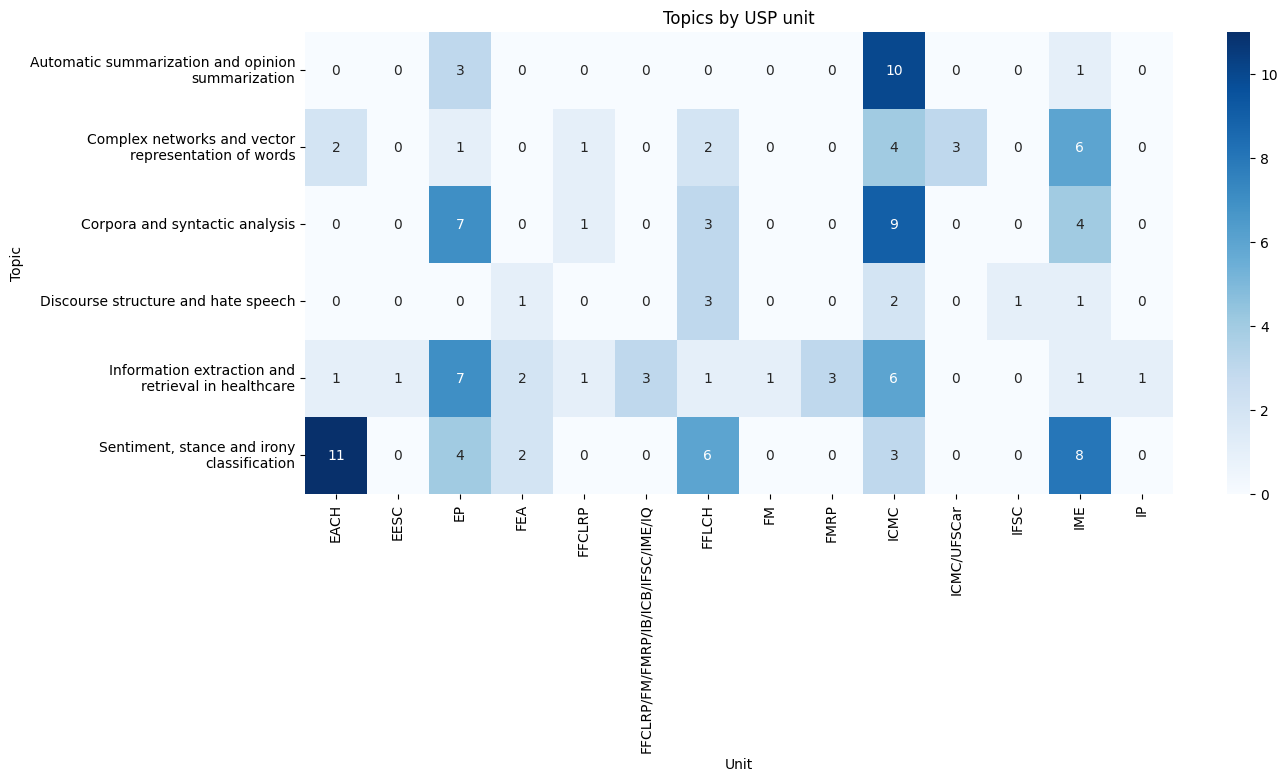

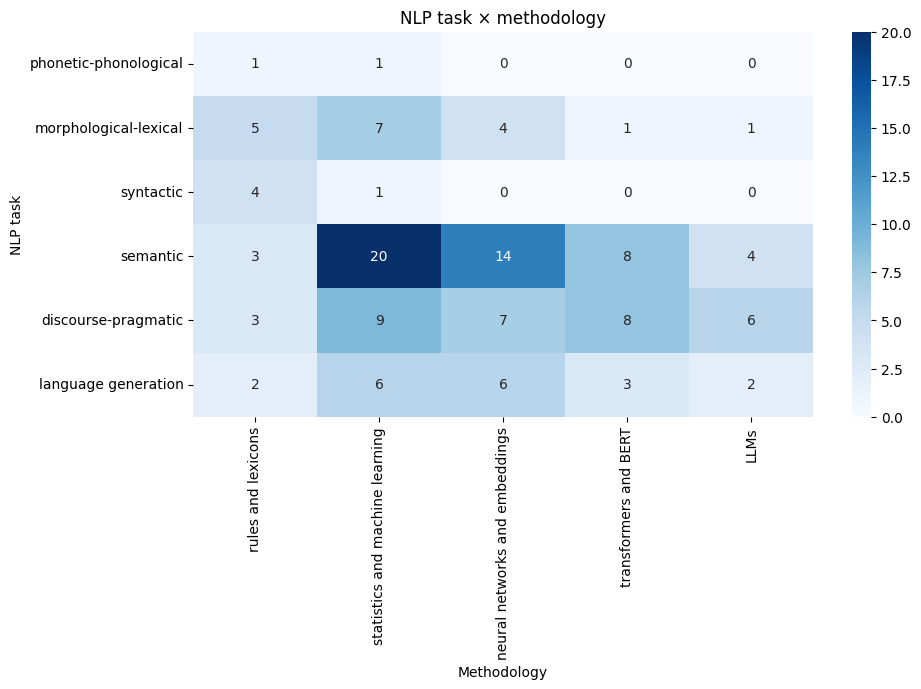

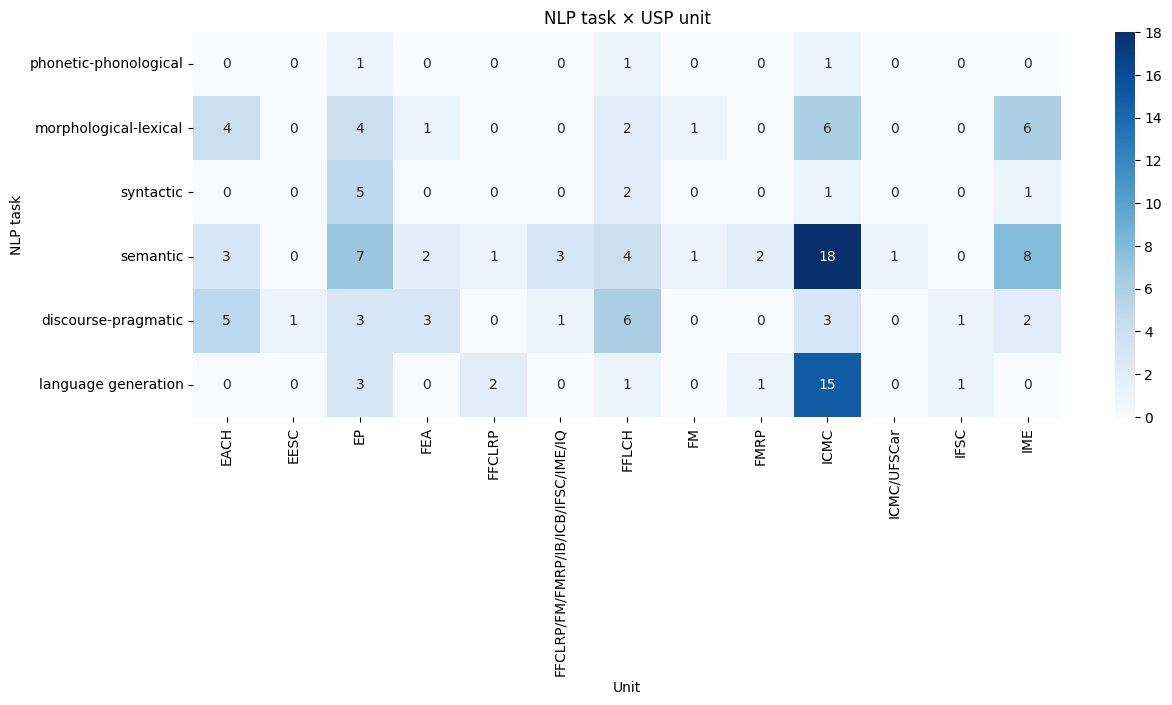

Works per methodology:


,methodology,number of works
0,rules and lexicons,12
1,statistics and machine learning,42
2,neural networks and embeddings,37
3,transformers and BERT,19
4,LLMs,15



NLP tasks and unused methodologies:


,NLP task,number of works,methodologies not yet used
0,phonetic-phonological,3,"neural networks and embeddings, transformers a..."
2,syntactic,9,"neural networks and embeddings, transformers a..."
5,language generation,23,—
1,morphological-lexical,24,—
4,discourse-pragmatic,25,—
3,semantic,50,—


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
import os
import sys
import shutil
import importlib
import subprocess
import textwrap
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import spacy
from spacy.matcher import PhraseMatcher
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF
from IPython.display import display
from google.colab import files

if not spacy.util.is_package('pt_core_news_lg'):
    subprocess.run([sys.executable, '-m', 'spacy', 'download', 'pt_core_news_lg'], check=True)
    importlib.invalidate_caches()
nlp = spacy.load('pt_core_news_lg')

print('Select the octoparse_thesis_scraping.csv file from your computer:')
uploaded_file = files.upload()
INPUT_FILE = list(uploaded_file.keys())[0]
RESULTS_FOLDER = 'RESULTS/'
NUMBER_OF_TOPICS = 6
shutil.rmtree(RESULTS_FOLDER, ignore_errors=True)
os.makedirs(RESULTS_FOLDER, exist_ok=True)

theses = pd.read_csv(INPUT_FILE, sep=None, engine='python', encoding='utf-8-sig')
print(len(theses), 'works loaded.')
dates = pd.to_datetime(theses['defense_date'], dayfirst=True, errors='coerce')
theses['year'] = dates.dt.year
theses['unit_acronym'] = theses['unit'].astype(str).str.extract(r'\(([^)]+)\)$')[0].str.strip()
print('Period:', theses['year'].min(), 'to', theses['year'].max())

works_per_year = theses['year'].value_counts()
works_per_year = works_per_year.sort_index()
plt.figure(figsize=(12, 4))
plt.bar(works_per_year.index, works_per_year.values)
plt.title('Works defended per year')
plt.xlabel('Year of defense')
plt.ylabel('Number of works')
plt.savefig(RESULTS_FOLDER + 'works_per_year.png', bbox_inches='tight')
plt.show()
works_per_unit = theses['unit_acronym'].value_counts()
works_per_unit = works_per_unit.sort_values()
plt.figure(figsize=(8, 5))
plt.barh(works_per_unit.index, works_per_unit.values)
plt.title('Works per USP unit')
plt.xlabel('Number of works')
plt.savefig(RESULTS_FOLDER + 'works_per_unit.png', bbox_inches='tight')
plt.show()

processed_abstracts = []
for abstract in theses['abstract']:
    document = nlp(abstract)
    processed_abstracts.append(document)

POS_NAMES = {
    'NOUN': 'noun', 'VERB': 'verb', 'ADJ': 'adjective', 'ADV': 'adverb',
    'PROPN': 'proper noun', 'ADP': 'preposition', 'DET': 'determiner', 'PRON': 'pronoun',
    'CCONJ': 'conjunction', 'AUX': 'auxiliary verb', 'NUM': 'numeral',
}
pos_counts = Counter()
for document in processed_abstracts:
    for token in document:
        if token.pos_ in POS_NAMES:
            name = POS_NAMES[token.pos_]
            pos_counts[name] += 1
pos_series = pd.Series(pos_counts)
pos_series = pos_series.sort_values()
plt.figure(figsize=(8, 5))
plt.barh(pos_series.index, pos_series.values)
plt.title('Parts of speech in the abstracts')
plt.xlabel('Number of words')
plt.savefig(RESULTS_FOLDER + 'parts_of_speech.png', bbox_inches='tight')
plt.show()

ACADEMIC_STOPWORDS = {
    'artigo', 'presente', 'trabalho', 'estudo', 'objetivo', 'resultado', 'análise', 'método', 'pesquisa', 'abordagem', 'proposta', 'dissertação',
    'tese', 'português', 'brasileiro', 'texto', 'área', 'campo', 'autor', 'autores', 'desenvolvimento', 'uso', 'utilização', 'modelo', 'tarefa'
}
BANNED_PHRASES = {
    'presente trabalho', 'este trabalho', 'deste trabalho', 'objetivo deste', 'língua português',
    'presente estudo', 'este estudo', 'deste estudo', 'resultado obtido', 'linguagem natural', 'língua natural', 'português brasileiro', 'grande quantidade', 'linguas naturais', 'bom resultado', 'bom desempenho', 'artigo científico'
}
CONTENT_POS = ['NOUN', 'ADJ', 'PROPN']
def important_words(document):
    result = []
    for token in document:
        lemma = token.lemma_.lower()
        if token.pos_ not in CONTENT_POS:
            continue
        if token.is_stop or not token.is_alpha or len(lemma) <= 2:
            continue
        if lemma in ACADEMIC_STOPWORDS:
            continue
        result.append(lemma)
    return result
def noun_phrases(document):
    result = []
    for chunk in document.noun_chunks:
        tokens = []
        for token in chunk:
            if not token.is_alpha:
                continue
            if token.i == chunk.start and token.is_stop:
                continue
            tokens.append(token.lemma_.lower())
        final_phrase = ' '.join(tokens).strip()
        if len(tokens) >= 2 and final_phrase not in BANNED_PHRASES:
            result.append(final_phrase)
    return result
all_words = []
all_phrases = []
for document in processed_abstracts:
    all_words.append(important_words(document))
    all_phrases.append(noun_phrases(document))
theses['words'] = all_words
theses['noun_phrases'] = all_phrases

word_counts = Counter()
phrase_counts = Counter()
for word_list in theses['words']:
    word_counts.update(word_list)
for phrase_list in theses['noun_phrases']:
    phrase_counts.update(phrase_list)
print('Distinct words:', len(word_counts))
print('Distinct noun phrases:', len(phrase_counts))
frequent_words = pd.Series(dict(word_counts.most_common(20)))
frequent_phrases = pd.Series(dict(phrase_counts.most_common(20)))
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].barh(frequent_words.index[::-1], frequent_words.values[::-1])
axes[0].set_title('Most frequent words')
axes[1].barh(frequent_phrases.index[::-1], frequent_phrases.values[::-1])
axes[1].set_title('Most frequent noun phrases')
plt.tight_layout()
plt.savefig(RESULTS_FOLDER + 'words_and_noun_phrases.png', bbox_inches='tight')
plt.show()

word_cloud = WordCloud(
    width=1200,
    height=600,
    background_color='white',
    colormap='viridis'
)
word_cloud.generate_from_frequencies(word_counts)

phrase_cloud = WordCloud(
    width=1200,
    height=600,
    background_color='white',
    colormap='plasma'
)
phrase_cloud.generate_from_frequencies(phrase_counts)

fig, axes = plt.subplots(1, 2, figsize=(20, 7))
axes[0].imshow(word_cloud)
axes[0].axis('off')
axes[0].set_title('Word cloud of the abstracts')

axes[1].imshow(phrase_cloud)
axes[1].axis('off')
axes[1].set_title('Noun phrase cloud of the abstracts')

plt.tight_layout()
plt.savefig(RESULTS_FOLDER + 'word_and_noun_phrase_clouds.png', bbox_inches='tight')
plt.show()

NLP_TASKS = {
    'phonetic-phonological': ['reconhecimento de fala', 'síntese de fala', 'speech recognition', 'text-to-speech',
                              'fala', 'prosódia', 'fonologia', 'fonético', 'fonema', 'acento'],
    'morphological-lexical': ['etiquetagem', 'etiquetador', 'part-of-speech', 'classe gramatical',
                              'classes gramaticais', 'análise morfológica', 'analisador morfológico',
                              'análise morfossintática', 'morfossintática', 'morfologia', 'lematização',
                              'lematizador', 'stemming', 'tokenização', 'léxico', 'léxicos', 'construção de um léxico',
                              'terminologia', 'dicionário', 'dicionários'],
    'syntactic': ['análise sintática', 'analisador sintático', 'parser', 'parsing', 'treebank', 'gramática',
                  'gramáticas', 'árvore sintática', 'dependências sintáticas', 'sintaxe'],
    'semantic': ['análise semântica', 'representação semântica', 'semântica lexical', 'papéis semânticos',
                 'desambiguação', 'implicação textual', 'similaridade semântica', 'ontologia', 'ontologias',
                 'entidades nomeadas', 'reconhecimento de entidades', 'named entity', 'extração de informação',
                 'extração de informações', 'análise de sentimento', 'análise de sentimentos', 'sentiment analysis',
                 'mineração de opinião', 'polaridade', 'classificação de textos', 'classificação de texto',
                 'classificação de documentos', 'text classification', 'classificação multirrótulo',
                 'recuperação de informação', 'recuperação de informações', 'information retrieval',
                 'busca semântica', 'sparql', 'modelagem de tópicos', 'modelo de tópicos', 'topic modeling'],
    'discourse-pragmatic': ['discurso', 'análise do discurso', 'coesão', 'coerência', 'anáfora', 'correferência',
                            'argumentação', 'argumentativo', 'diálogo', 'perguntas e respostas',
                            'question answering', 'chatbot', 'agente conversacional', 'ironia', 'sarcasmo',
                            'discurso de ódio', 'hate speech', 'posicionamento', 'desinformação', 'fake news'],
    'language generation': ['geração de texto', 'geração automática', 'geração de linguagem', 'text generation',
                            'tradução automática', 'tradutor automático', 'machine translation', 'sumarização',
                            'summarization', 'sumário automático', 'simplificação textual', 'simplificação de textos',
                            'paráfrase'],
}
METHODOLOGIES = {
    'rules and lexicons': ['baseado em regras', 'baseada em regras', 'rule-based', 'regras linguísticas',
                           'baseado em léxico', 'baseada em léxico', 'autômatos', 'lógica', 'sistema especialista'],
    'statistics and machine learning': ['aprendizado de máquina', 'machine learning', 'aprendizado computacional',
                                        'aprendizagem de máquina', 'aprendizado supervisionado', 'svm',
                                        'naive bayes', 'random forest', 'regressão logística', 'crf',
                                        'cadeias de markov', 'modelos estatísticos', 'tf-idf'],
    'neural networks and embeddings': ['rede neural', 'redes neurais', 'neural network', 'lstm', 'cnn', 'word2vec',
                                       'word embeddings', 'embeddings', 'aprendizado profundo', 'deep learning',
                                       'representação vetorial', 'representações vetoriais'],
    'transformers and BERT': ['transformer', 'transformers', 'bert', 'bertimbau', 'roberta', 'atenção neural',
                              'pré-treinado', 'pré-treinados', 'ajuste fino', 'fine-tuning'],
    'LLMs': ['llm', 'llms', 'grandes modelos de linguagem', 'large language model', 'gpt', 'chatgpt',
             'llama', 'prompt', 'prompts', 'engenharia de prompt', 'zero-shot', 'few-shot'],
}

def create_matcher(dictionary):
    matcher = PhraseMatcher(nlp.vocab, attr='LOWER')
    for name, expressions in dictionary.items():
        patterns = []
        for expression in expressions:
            patterns.append(nlp.make_doc(expression))
        matcher.add(name, patterns)
    return matcher
def find_matches(matcher, document):
    found = set()
    for match_id, start, end in matcher(document):
        name = nlp.vocab.strings[match_id]
        found.add(name)
    return sorted(found)
task_matcher = create_matcher(NLP_TASKS)
methodology_matcher = create_matcher(METHODOLOGIES)
task_list = []
methodology_list = []
for i in range(len(theses)):
    full_text = theses['title'][i] + '. ' + theses['keywords'][i] + '. ' + theses['abstract'][i]
    document = nlp.make_doc(full_text)
    task_list.append(find_matches(task_matcher, document))
    methodology_list.append(find_matches(methodology_matcher, document))
theses['tasks'] = task_list
theses['methodology'] = methodology_list
no_task = 0
no_methodology = 0
for i in range(len(theses)):
    if len(theses['tasks'][i]) == 0:
        no_task += 1
    if len(theses['methodology'][i]) == 0:
        no_methodology += 1
print('Works with no task identified:', no_task, 'of', len(theses))
print('Works with no methodology identified:', no_methodology, 'of', len(theses))

task_rows = []
methodology_rows = []
cross_rows = []
for i in range(len(theses)):
    for task in theses['tasks'][i]:
        task_rows.append({'doi': theses['doi'][i], 'year': theses['year'][i],
                          'unit_acronym': theses['unit_acronym'][i], 'task': task})
        for methodology in theses['methodology'][i]:
            cross_rows.append({'task': task, 'methodology': methodology})
    for methodology in theses['methodology'][i]:
        methodology_rows.append({'year': theses['year'][i], 'methodology': methodology})
tasks_per_work = pd.DataFrame(task_rows)
methodology_per_work = pd.DataFrame(methodology_rows)
task_and_methodology = pd.DataFrame(cross_rows)
task_counts = tasks_per_work['task'].value_counts()
task_counts = task_counts.reindex(list(NLP_TASKS)[::-1], fill_value=0)
methodology_counts = methodology_per_work['methodology'].value_counts()
methodology_counts = methodology_counts.sort_values()
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].barh(task_counts.index, task_counts.values)
axes[0].set_title('NLP tasks by architecture level (number of works)')
axes[1].barh(methodology_counts.index, methodology_counts.values, color='darkorange')
axes[1].set_title('Methodology (number of works)')
plt.tight_layout()
plt.savefig(RESULTS_FOLDER + 'tasks_and_methodology.png', bbox_inches='tight')
plt.show()
methodology_per_year = pd.crosstab(methodology_per_work['year'], methodology_per_work['methodology'])
methodology_per_year.plot(kind='bar', stacked=True, figsize=(14, 5))
plt.title('Methodology by year of defense')
plt.xlabel('Year of defense')
plt.ylabel('Number of works')
plt.legend(title='Methodology')
plt.savefig(RESULTS_FOLDER + 'methodology_per_year.png', bbox_inches='tight')
plt.show()

topic_texts = []
for words in theses['words']:
    topic_texts.append(' '.join(words))
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.9)
tfidf_matrix = tfidf.fit_transform(topic_texts)
vocabulary = tfidf.get_feature_names_out()
topic_model = NMF(n_components=NUMBER_OF_TOPICS, random_state=42, init='nndsvda', max_iter=500)
topic_weights = topic_model.fit_transform(tfidf_matrix)

automatic_names = []
topic_terms = []
for weights in topic_model.components_:
    positions = weights.argsort()[::-1][:10]
    terms = []
    for position in positions:
        terms.append(vocabulary[position])
    topic_terms.append(terms)
    automatic_names.append(', '.join(terms[:3]))
topic_of_each_work = []
for weights in topic_weights:
    number = weights.argmax()
    topic_of_each_work.append(automatic_names[number])
theses['topic'] = topic_of_each_work

topics = pd.DataFrame({'topic': automatic_names, 'top terms': topic_terms})
works_per_topic = theses['topic'].value_counts()
topics['number of works'] = topics['topic'].map(works_per_topic)
display(topics[['topic', 'number of works']])
THEMATIC_NAMES = {
    'informação, pln, médico': 'Information extraction and retrieval in healthcare',
    'sumarização, opinião, sumário': 'Automatic summarization and opinion summarization',
    'corpus, sintático, aps': 'Corpora and syntactic analysis',
    'palavra, rede, representação': 'Complex networks and vector representation of words',
    'sentimento, dado, classificação': 'Sentiment, stance and irony classification',
    'discurso, ódio, discurso ódio': 'Discourse structure and hate speech',
}
untranslated = [name for name in automatic_names if name not in THEMATIC_NAMES]
if untranslated:
    print('Warning: these automatic names are not in THEMATIC_NAMES:')
    for name in untranslated:
        print('-', name)
    print('Copy the exact name above into the dictionary and run it again.')
topic_names = []
for name in automatic_names:
    topic_names.append(THEMATIC_NAMES.get(name, name))
theses['topic'] = theses['topic'].map(lambda name: THEMATIC_NAMES.get(name, name))
topics['topic'] = topic_names
name_mapping = pd.DataFrame({
    'automatic name': automatic_names,
    'thematic name': topic_names,
})
display(name_mapping)
columns = 3
rows = (NUMBER_OF_TOPICS + columns - 1) // columns
fig, axes = plt.subplots(rows, columns, figsize=(18, 5 * rows))
axes = axes.flatten()
for number in range(NUMBER_OF_TOPICS):
    weights = topic_model.components_[number]
    frequencies = {}
    for position in weights.argsort()[::-1][:40]:
        frequencies[vocabulary[position]] = weights[position]
    cloud = WordCloud(width=600, height=400, background_color='white', colormap='viridis')
    cloud.generate_from_frequencies(frequencies)
    axes[number].imshow(cloud)
    axes[number].set_title(textwrap.fill('Topic: ' + topic_names[number], 45))
    axes[number].axis('off')
for number in range(NUMBER_OF_TOPICS, len(axes)):
    axes[number].axis('off')
plt.tight_layout()
plt.savefig(RESULTS_FOLDER + 'topic_clouds.png', bbox_inches='tight')
plt.show()
topic_by_unit = pd.crosstab(theses['topic'], theses['unit_acronym'])
topic_by_unit.index = [textwrap.fill(name, 35) for name in topic_by_unit.index]
plt.figure(figsize=(14, 6))
sns.heatmap(topic_by_unit, annot=True, fmt='d', cmap='Blues')
plt.title('Topics by USP unit')
plt.xlabel('Unit')
plt.ylabel('Topic')
plt.savefig(RESULTS_FOLDER + 'topics_by_unit.png', bbox_inches='tight')
plt.show()

task_x_methodology = pd.crosstab(task_and_methodology['task'], task_and_methodology['methodology'])
task_x_methodology = task_x_methodology.reindex(index=list(NLP_TASKS), columns=list(METHODOLOGIES), fill_value=0)
plt.figure(figsize=(10, 5))
sns.heatmap(task_x_methodology, annot=True, fmt='d', cmap='Blues')
plt.title('NLP task × methodology')
plt.xlabel('Methodology')
plt.ylabel('NLP task')
plt.savefig(RESULTS_FOLDER + 'gaps_task_methodology.png', bbox_inches='tight')
plt.show()
task_x_unit = pd.crosstab(tasks_per_work['task'], tasks_per_work['unit_acronym'])
task_x_unit = task_x_unit.reindex(list(NLP_TASKS), fill_value=0)
plt.figure(figsize=(14, 5))
sns.heatmap(task_x_unit, annot=True, fmt='d', cmap='Blues')
plt.title('NLP task × USP unit')
plt.xlabel('Unit')
plt.ylabel('NLP task')
plt.savefig(RESULTS_FOLDER + 'gaps_task_unit.png', bbox_inches='tight')
plt.show()

methodology_table = methodology_counts.reindex(list(METHODOLOGIES), fill_value=0)
methodology_table = pd.DataFrame({
    'methodology': methodology_table.index,
    'number of works': methodology_table.values,
})
print('Works per methodology:')
display(methodology_table)
total_per_task = task_counts.reindex(list(NLP_TASKS), fill_value=0)
gaps = []
for task in NLP_TASKS:
    unused_methodologies = []
    for methodology in METHODOLOGIES:
        if task_x_methodology.loc[task, methodology] == 0:
            unused_methodologies.append(methodology)
    gaps.append({
        'NLP task': task,
        'number of works': int(total_per_task[task]),
        'methodologies not yet used': ', '.join(unused_methodologies) if unused_methodologies else '—',
    })
gaps = pd.DataFrame(gaps)
gaps = gaps.sort_values('number of works')
print()
print('NLP tasks and unused methodologies:')
display(gaps)

classified_works = pd.DataFrame({
    'doi': theses['doi'],
    'title': theses['title'],
    'topic': theses['topic'],
})
tasks_as_text = []
methodology_as_text = []
for i in range(len(theses)):
    tasks_as_text.append('; '.join(theses['tasks'][i]))
    methodology_as_text.append('; '.join(theses['methodology'][i]))
classified_works['nlp_tasks'] = tasks_as_text
classified_works['methodology'] = methodology_as_text
classified_works.to_csv(RESULTS_FOLDER + 'classified_works.csv', index=False, encoding='utf-8-sig')
topics.to_csv(RESULTS_FOLDER + 'topics.csv', index=False, encoding='utf-8-sig')
methodology_table.to_csv(RESULTS_FOLDER + 'methodologies.csv', index=False, encoding='utf-8-sig')
gaps.to_csv(RESULTS_FOLDER + 'gaps.csv', index=False, encoding='utf-8-sig')
shutil.make_archive('results', 'zip', root_dir='.', base_dir=RESULTS_FOLDER)
files.download('results.zip')
